In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('data/NGDB_merged_clean.csv', low_memory=False)
df.head()

,LAB_ID,LAB_ID.1,JOB_ID,SUBMITTER,DATE_SUB,FIELD_ID,STATE,COUNTRY,DATUM,SPHEROID,...,VPPM_XRFQ,WPPM_XRF,WPPM_XRFQ,YPPM_XRF,YPPM_XRFQ,YBPPM_XRFQ,ZNPPM_XRF,ZNPPM_XRFQ,ZRPPM_XRF,ZRPPM_XRFQ
0,AAM051,AAM051,HM860,"Lesure, Frank G.",1967-07-03,M40,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AAM051A,AAM051A,HM860,"Lesure, Frank G.",1967-07-03,M40,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AAM052,AAM052,HM860,"Lesure, Frank G.",1967-07-03,M41,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AAM052A,AAM052A,HM860,"Lesure, Frank G.",1967-07-03,M41,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AAM053,AAM053,HM860,"Lesure, Frank G.",1967-07-03,M42,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print(df.shape)
df.info()

(414304, 269)
<class 'pandas.DataFrame'>
RangeIndex: 414304 entries, 0 to 414303
Columns: 269 entries, LAB_ID to ZRPPM_XRFQ
dtypes: float64(129), str(140)
memory usage: 850.3 MB


In [4]:
df.describe()

,LATITUDE,LONGITUDE,SIO2_XRF,SIO2_GRV,SIO2_AES,SIO2_AA,SIO2_CLR,SIO2_UNK,AL2O3_XRF,AL2O3_GRV,...,SNPPM_XRF,SRPPM_XRF,THPPM_XRF,TMPPM_XRF,UPPM_XRF,VPPM_XRF,WPPM_XRF,YPPM_XRF,ZNPPM_XRF,ZRPPM_XRF
count,414304.000000,414304.000000,76424.000000,190.000000,841.000000,3524.000000,4498.000000,29134.000000,76424.000000,190.000000,...,4310.000000,37042.000000,4267.000000,15.000000,4267.000000,4376.000000,3642.000000,35774.000000,27007.000000,36042.000000
mean,44.455293,-115.797227,59.116939,50.515474,14.928407,56.904083,57.164595,58.037901,13.924687,13.033789,...,2.974014,432.572642,5.174361,66.813333,11.585657,199.940128,20.836903,30.782048,129.688155,178.690752
std,12.727160,33.985792,13.782980,3.608184,20.020951,13.276437,13.800623,18.388102,4.579001,1.873855,...,8.330060,1696.336386,9.489529,48.580344,30.752599,291.987193,57.222193,41.335003,505.159916,175.531745
min,-113.816940,-179.745000,0.100000,44.760000,0.100000,0.430000,0.010000,0.010000,0.010000,8.110000,...,2.000000,2.000000,2.000000,0.300000,2.000000,2.000000,5.000000,2.000000,2.000000,2.000000
25%,37.866670,-132.282500,50.300000,49.362500,4.200000,48.800000,48.300000,49.370000,12.700000,12.552500,...,2.000000,146.000000,2.000000,0.550000,2.000000,79.000000,5.000000,17.000000,55.000000,95.000000
50%,42.882780,-115.987780,59.400000,50.535000,7.400000,52.800000,58.500000,59.900000,14.900000,13.520000,...,2.000000,317.000000,4.000000,100.000000,4.000000,172.000000,5.000000,24.000000,74.000000,148.000000
75%,55.175830,-108.963890,69.100000,50.840000,13.500000,68.100000,67.900000,70.700000,16.600000,13.805000,...,2.000000,550.000000,5.000000,100.000000,5.000000,233.000000,5.000000,33.000000,97.000000,220.000000
max,74.833330,179.919170,99.600000,64.410000,93.800000,98.300000,97.200000,100.000000,58.000000,18.080000,...,313.000000,140000.000000,318.000000,100.000000,549.000000,8480.000000,852.000000,3000.000000,20100.000000,16200.000000


In [5]:
print("SNPPM_XRF:", df['SNPPM_XRF'].notnull().sum())
print("MGO_XRF:", df['MGO_XRF'].notnull().sum())

SNPPM_XRF: 4310
MGO_XRF: 76408


In [6]:
df[['LATITUDE', 'LONGITUDE', 'SIO2_XRF', 'AL2O3_XRF', 'SNPPM_XRF', 'MGO_XRF']].isnull().sum()

LATITUDE          0
LONGITUDE         0
SIO2_XRF     337880
AL2O3_XRF    337880
SNPPM_XRF    409994
MGO_XRF      337896
dtype: int64

In [7]:

geo = df[df['LATITUDE'].between(-90, 90) & df['LONGITUDE'].between(-180, 180)]
geo = geo[geo['LATITUDE'].between(24, 72) & geo['LONGITUDE'].between(-170, -50)]
ata = geo.dropna(subset=['LATITUDE', 'LONGITUDE', 'SIO2_XRF', 'AL2O3_XRF', 'MGO_XRF']).copy()

In [8]:
cols = ['LATITUDE','LONGITUDE','SIO2_XRF','AL2O3_XRF','MGO_XRF']
print('Duplikat:', ata.duplicated(subset=cols).sum())
print(ata[['SIO2_XRF','AL2O3_XRF','MGO_XRF']].describe())
print('SiO2<20:', (ata['SIO2_XRF']<20).sum(), '| Al2O3>30:', (ata['Al2O3_XRF']>30).sum() if 'Al2O3_XRF' in ata else (ata['AL2O3_XRF']>30).sum())

Duplikat: 32
           SIO2_XRF     AL2O3_XRF       MGO_XRF
count  68126.000000  68126.000000  68126.000000
mean      59.782466     13.977291      3.562254
std       13.662718      4.588433      4.569092
min        0.100000      0.010000      0.010000
25%       50.900000     12.600000      0.710000
50%       60.400000     15.000000      2.280000
75%       69.600000     16.700000      4.920000
max       99.600000     58.000000     47.600000
SiO2<20: 1131 | Al2O3>30: 155


In [9]:
print('Real Sn values:', ata['SNPPM_XRF'].notna().sum(), 'of', len(ata))
print('Share of real values at 2 ppm:', round((ata['SNPPM_XRF'].dropna() == 2).mean(), 3))

Real Sn values: 3087 of 68126
Share of real values at 2 ppm: 0.857


In [10]:
print(ata['SNPPM_XRFQ'].value_counts(dropna=False))
print(ata['SNPPM_XRF'].value_counts().head(10))

SNPPM_XRFQ
NaN    65707
<       2392
L         27
Name: count, dtype: int64
SNPPM_XRF
2.0     2647
3.0      205
4.0       87
5.0       47
6.0       26
10.0      17
7.0       11
8.0        8
12.0       5
11.0       4
Name: count, dtype: int64


In [11]:
print("new_data", ata.shape)

new_data (68126, 269)


In [12]:
ata[['LATITUDE', 'LONGITUDE', 'SIO2_XRF', 'AL2O3_XRF', 'SNPPM_XRF', 'MGO_XRF']].head()

,LATITUDE,LONGITUDE,SIO2_XRF,AL2O3_XRF,SNPPM_XRF,MGO_XRF
35194,48.10833,-88.60667,47.8,15.7,NaN,7.35
35195,48.10333,-88.59917,47.7,16.3,NaN,4.25
35196,48.09889,-88.61555,49.9,12.8,NaN,4.72
35197,48.09499,-88.61222,47.1,17.6,NaN,6.39
35198,48.11805,-88.51889,44.6,15.8,NaN,8.07


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score,  davies_bouldin_score
import folium

In [14]:
fitur = ['SIO2_XRF', 'AL2O3_XRF', 'MGO_XRF']
X = ata[fitur]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [15]:
from sklearn.cluster import KMeans

In [16]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
ata['Mineral_group'] = kmeans.fit_predict(X_scaled)

ata[['LATITUDE', 'LONGITUDE', 'SIO2_XRF', 'AL2O3_XRF', 'MGO_XRF', 'Mineral_group']].head()

,LATITUDE,LONGITUDE,SIO2_XRF,AL2O3_XRF,MGO_XRF,Mineral_group
35194,48.10833,-88.60667,47.8,15.7,7.35,0
35195,48.10333,-88.59917,47.7,16.3,4.25,0
35196,48.09889,-88.61555,49.9,12.8,4.72,0
35197,48.09499,-88.61222,47.1,17.6,6.39,0
35198,48.11805,-88.51889,44.6,15.8,8.07,0


In [17]:
print("isnull?:", np.isnan(X_scaled).any())

isnull?: False


In [18]:
ata['Mineral_group'].value_counts()

Mineral_group
0    34725
2    28578
1     4823
Name: count, dtype: int64

In [19]:
ata.groupby('Mineral_group')[['SIO2_XRF', 'AL2O3_XRF', 'MGO_XRF']].mean()

,SIO2_XRF,AL2O3_XRF,MGO_XRF
Mineral_group,,,
0,53.778871,16.579085,4.556010
1,32.949254,4.804854,12.094435
2,71.605946,12.363861,0.914803


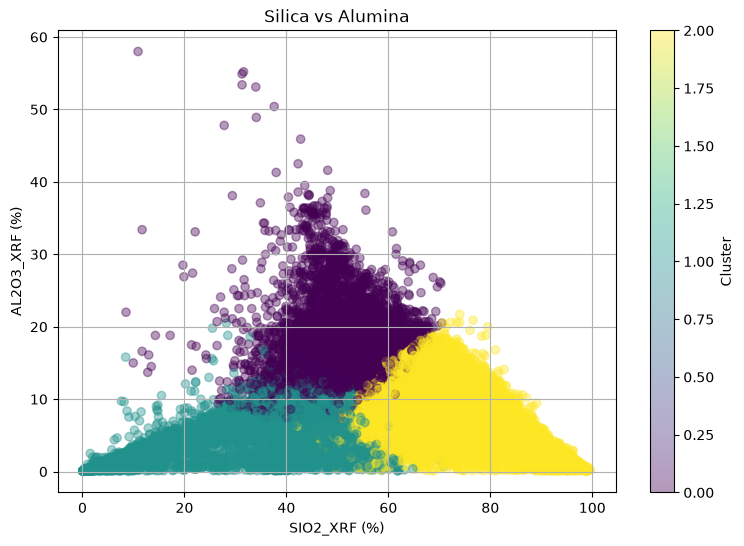

In [20]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    ata['SIO2_XRF'],
    ata['AL2O3_XRF'],
    c=ata['Mineral_group'],
    cmap='viridis',
    alpha=0.4
)

plt.title('Silica vs Alumina')
plt.xlabel('SIO2_XRF (%)')
plt.ylabel('AL2O3_XRF (%)')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

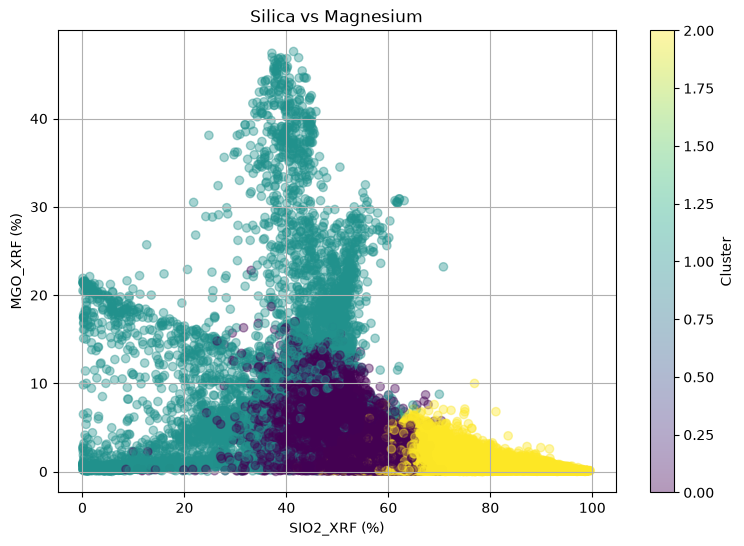

In [21]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    ata['SIO2_XRF'],
    ata['MGO_XRF'],
    c=ata['Mineral_group'],
    cmap='viridis',
    alpha=0.4
)

plt.title('Silica vs Magnesium')
plt.xlabel('SIO2_XRF (%)')
plt.ylabel('MGO_XRF (%)')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

In [22]:
ata[['SIO2_XRF', 'AL2O3_XRF', 'MGO_XRF']].corr()

,SIO2_XRF,AL2O3_XRF,MGO_XRF
SIO2_XRF,1.000000,-0.034079,-0.535501
AL2O3_XRF,-0.034079,1.000000,-0.175519
MGO_XRF,-0.535501,-0.175519,1.000000


In [23]:
cluster_mean = ata.groupby('Mineral_group')[['SIO2_XRF', 'AL2O3_XRF', 'MGO_XRF', 'LATITUDE', 'LONGITUDE']].mean()
print(cluster_mean.round(2))

               SIO2_XRF  AL2O3_XRF  MGO_XRF  LATITUDE  LONGITUDE
Mineral_group                                                   
0                 53.78      16.58     4.56     45.20    -119.13
1                 32.95       4.80    12.09     42.02    -111.73
2                 71.61      12.36     0.91     43.01    -115.88


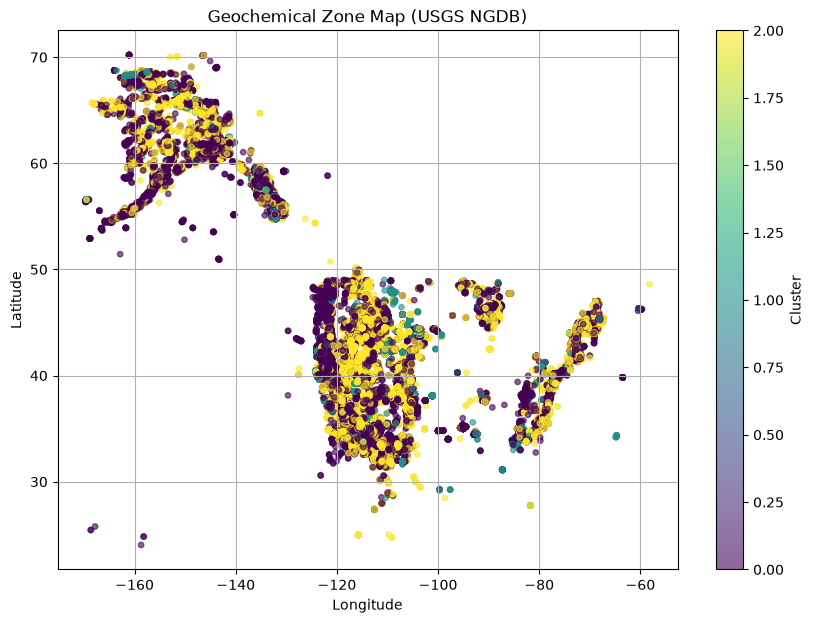

In [24]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    ata['LONGITUDE'],
    ata['LATITUDE'],
    c=ata['Mineral_group'],
    cmap='viridis',
    s=15,
    alpha=0.6
)

plt.title('Geochemical Zone Map (USGS NGDB)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

In [25]:
inertia_list = []
sil_list = []
db_list = []
k_range = range(2, 8)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_scaled, labels, sample_size=20000, random_state=42))
    db_list.append(davies_bouldin_score(X_scaled, labels))
    print(k, round(km.inertia_, 1), round(sil_list[-1], 4), round(db_list[-1], 4))

2 140842.6 0.3914 1.1148
3 95639.5 0.4138 0.9338
4 74253.5 0.43 0.8248
5 56533.4 0.4346 0.7751
6 45657.5 0.4017 0.8064
7 40744.3 0.4025 0.8488


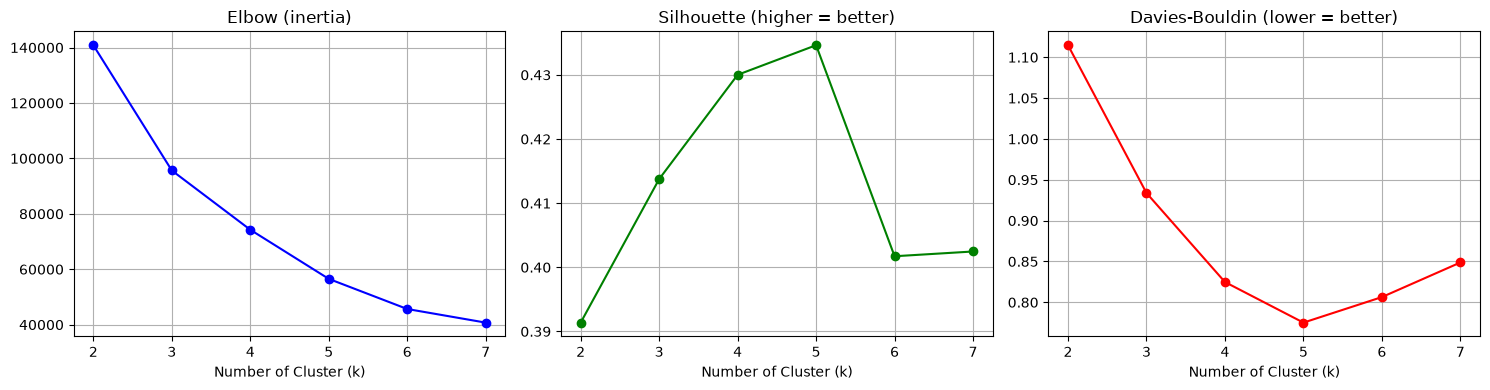

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(k_range, inertia_list, 'bo-'); ax[0].set_title('Elbow (inertia)')
ax[1].plot(k_range, sil_list, 'go-'); ax[1].set_title('Silhouette (higher = better)')
ax[2].plot(k_range, db_list, 'ro-'); ax[2].set_title('Davies-Bouldin (lower = better)')
for a in ax:
    a.set_xlabel('Number of Cluster (k)')
    a.grid(True)
plt.tight_layout()
plt.savefig('fig_k_selection.png', dpi=200)
plt.show()

In [27]:
ata_score = silhouette_score(X_scaled, ata['Mineral_group'], sample_size=20000, random_state=42)
ata_db = davies_bouldin_score(X_scaled, ata['Mineral_group'])
print(f"Silhouette Score untuk k = 3: {ata_score:.4f}")
print(f"Davies-Bouldin Index untuk k = 3: {ata_db:.4f}")

Silhouette Score untuk k = 3: 0.4138
Davies-Bouldin Index untuk k = 3: 0.9338


In [28]:
center_lat = ata['LATITUDE'].mean()
center_lon = ata['LONGITUDE'].mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=3, tiles='OpenStreetMap')
color_map = {0: 'gray', 1: 'blue', 2: 'red'}
sample_data = ata.sample(n=min(3000, len(ata)), random_state=42)

for _, row in sample_data.iterrows():
    c_id = int(row['Mineral_group'])
    folium.CircleMarker(
        location=[row['LATITUDE'], row['LONGITUDE']],
        radius=3,
        color=color_map[c_id],
        fill=True,
        fill_color=color_map[c_id],
        fill_opacity=0.6,
        popup=f"Cluster: {c_id}"
    ).add_to(m)

for _, row in ata[ata['SNPPM_XRF'].notna() & ata['SNPPM_XRFQ'].isna()].iterrows():
    folium.CircleMarker(
        location=[row['LATITUDE'], row['LONGITUDE']],
        radius=5, color='black', weight=2, fill=False,
        popup=f"Sn detected: {row['SNPPM_XRF']} ppm"
    ).add_to(m)

m.save('Interactive_Geochemical_Zone_Map.html')
m

In [29]:
sn_real = ata.dropna(subset=['SNPPM_XRF']).copy()
sn_real['Sn_detected'] = sn_real['SNPPM_XRFQ'].isna()
tab = sn_real.groupby('Mineral_group')['Sn_detected'].agg(['sum', 'count'])
tab['detection_rate'] = (tab['sum'] / tab['count']).round(3)
print(tab)
print('Overall detection rate:', round(sn_real['Sn_detected'].mean(), 3))

               sum  count  detection_rate
Mineral_group                            
0              250   2276           0.110
1               10     53           0.189
2              408    758           0.538
Overall detection rate: 0.216


In [30]:
from scipy.stats import chi2_contingency
ct = pd.crosstab(sn_real['Mineral_group'], sn_real['Sn_detected'])
chi2, p, dof, _ = chi2_contingency(ct)
print(ct)
print(f'chi2={chi2:.2f}, p={p:.2e}')

Sn_detected    False  True 
Mineral_group              
0               2026    250
1                 43     10
2                350    408
chi2=615.73, p=1.97e-134


In [31]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
ata['group_k5'] = km5.fit_predict(X_scaled)
print(ata['group_k5'].value_counts())
print(ata.groupby('group_k5')[['SIO2_XRF', 'AL2O3_XRF', 'MGO_XRF']].mean().round(2))

group_k5
1    30967
3    27535
0     4752
2     3402
4     1470
Name: count, dtype: int64
          SIO2_XRF  AL2O3_XRF  MGO_XRF
group_k5                              
0            79.58       5.14     1.16
1            68.17      14.46     1.14
2            29.47       4.88     4.85
3            51.72      16.61     5.35
4            40.21       4.10    25.90


In [32]:
print([c for c in df.columns if 'DATE' in c.upper()])
print(sorted({c.split('_')[-1] for c in df.columns if '_' in c})[:40])

['DATE_SUB', 'DATECOLLCT']
['AA', 'AAQ', 'AES', 'AESQ', 'AGE', 'ATTR', 'CLR', 'CLRQ', 'CMB', 'CMBQ', 'DESC', 'DFF', 'DFFQ', 'ELCTRD', 'ELCTRDQ', 'ENVIRN', 'GRD', 'GRV', 'GRVQ', 'ID', 'ID.1', 'MSC', 'MSCQ', 'NAME', 'RK', 'SIZE', 'SRC', 'SUB', 'TTR', 'TTRQ', 'UNK', 'UNKQ', 'XRF', 'XRFQ']


In [33]:
d = pd.to_datetime(df['DATECOLLCT'], errors='coerce')
print(d.min(), d.max(), d.notna().sum())

1953-06-01 00:00:00 2003-10-24 00:00:00 7223


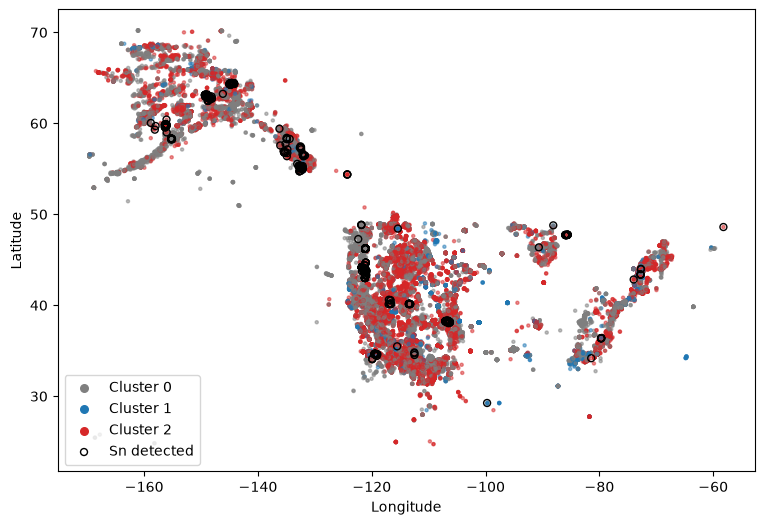

In [35]:
colors = {0: '#7f7f7f', 1: '#1f77b4', 2: '#d62728'}
plot_df = ata.sample(frac=1, random_state=42)   
plt.figure(figsize=(9, 6))
plt.scatter(plot_df['LONGITUDE'], plot_df['LATITUDE'],
            c=plot_df['Mineral_group'].map(colors), s=5, alpha=0.5)

for g in [0, 1, 2]:
    plt.scatter([], [], c=colors[g], s=30, label=f'Cluster {g}')

sn = sn_real[sn_real['Sn_detected']]
plt.scatter(sn['LONGITUDE'], sn['LATITUDE'], facecolors='none',
            edgecolors='black', s=25, label='Sn detected')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.legend(loc='lower left')
plt.savefig('zone_map.png', dpi=200, bbox_inches='tight')
plt.show()